<a href="https://colab.research.google.com/github/isti2415/CSC551-Data-Mining/blob/main/Assignment%201/Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1: Date Fruit Dataset (Python / NumPy basics)

## Setup

We need these libraries:
- `pandas` to read the Excel file into a table (data frame)
- `numpy` for arrays and vectorised maths
- `plotly` for interactive plots (we can rotate and zoom them)
- `matplotlib` for the circle segment plot
- `kagglehub` to download the dataset, `openpyxl` so pandas can read `.xlsx`

In [ ]:
%pip install -q kagglehub pandas numpy plotly matplotlib openpyxl nbformat

In [ ]:
import os
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Patch
import kagglehub

## Task 1: Download the dataset

The Date Fruit dataset has measurements (size, shape, colour features) of date fruit images. The last column, `Class`, tells which type of date it is. We download it with `kagglehub`.

In [ ]:
path = kagglehub.dataset_download("muratkokludataset/date-fruit-datasets")
print("Path to dataset files:", path)

for folder, _, files in os.walk(path):
    for f in files:
        print(os.path.join(folder, f))

100%|██████████| 408k/408k [00:00<00:00, 18.8MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/muratkokludataset/date-fruit-datasets/versions/1
/root/.cache/kagglehub/datasets/muratkokludataset/date-fruit-datasets/versions/1/Date_Fruit_Datasets/Date_Fruit_Datasets.arff
/root/.cache/kagglehub/datasets/muratkokludataset/date-fruit-datasets/versions/1/Date_Fruit_Datasets/Date_Fruit_Datasets.xlsx
/root/.cache/kagglehub/datasets/muratkokludataset/date-fruit-datasets/versions/1/Date_Fruit_Datasets/Date_Fruit_Datasets_Citation_Request.txt


## Task 2: Read the xlsx file with pandas

We search the downloaded folder for the `.xlsx` file and load it into a data frame. `shape` shows (rows, columns).

In [ ]:
xlsx_file = [os.path.join(folder, f)
             for folder, _, files in os.walk(path)
             for f in files if f.endswith(".xlsx")][0]

df_full = pd.read_excel(xlsx_file)
print(df_full.shape)
df_full.head()

(898, 35)


,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [ ]:
print(df_full["Class"].value_counts())

Class
DOKOL     204
SAFAVI    199
ROTANA    166
DEGLET     98
SOGAY      94
IRAQI      72
BERHI      65
Name: count, dtype: int64


## Task 3: Keep the first three dimensions and the class label

We only need the first three real-valued columns and the last column (the class label), so the new data frame has four columns. We also remember the full table (`df_full`) because tasks 15 and 16 need the first 7 dimensions.

In [ ]:
df = df_full.iloc[:, [0, 1, 2, -1]]
feature_names = list(df.columns[:3])
print(feature_names)
df.head()

['AREA', 'PERIMETER', 'MAJOR_AXIS']


,AREA,PERIMETER,MAJOR_AXIS,Class
0,422163,2378.908,837.8484,BERHI
1,338136,2085.144,723.8198,BERHI
2,526843,2647.394,940.7379,BERHI
3,416063,2351.210,827.9804,BERHI
4,347562,2160.354,763.9877,BERHI


## Task 4: Convert to a NumPy array

- `data` is the whole data frame as a NumPy array.
- `X` holds the three numeric features.
- The class labels are strings, so we convert them to numbers 0, 1, 2, ... in `y`.
- `class_names` is a list of the class names, so `class_names[2]` gives the name of class 2.

In [ ]:
data = df.to_numpy()

X = data[:, :3].astype(float)
class_names, y = np.unique(data[:, 3], return_inverse=True)
class_names = list(class_names)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", class_names)
print("Class of first row:", y[0], "->", class_names[y[0]])

X shape: (898, 3)
y shape: (898,)
Classes: ['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY']
Class of first row: 0 -> BERHI


## Task 5: Plotly for interactive plots

Plotly makes plots we can rotate, zoom, and hover over. For each class we need a different **shape**, so we prepare one marker shape and one colour per class. (Plotly 3D plots support fewer marker shapes than 2D plots, so the 3D list is different.)

In [ ]:
symbols_2d = ["triangle-up", "square", "circle", "diamond", "star", "cross", "x"]
symbols_3d = ["circle", "square", "diamond", "cross", "x", "circle-open", "square-open"]
colors = px.colors.qualitative.Plotly

## Task 6: 2D plot using the first two dimensions

We draw one set of points per class, each class with its own shape. The function is reused later in task 8.

In [ ]:
def make_2d_figure():
    fig = go.Figure()
    for k, name in enumerate(class_names):
        pts = X[y == k]
        fig.add_trace(go.Scatter(
            x=pts[:, 0], y=pts[:, 1], mode="markers", name=name,
            marker=dict(symbol=symbols_2d[k], size=8, color=colors[k])))
    fig.update_layout(title="2D scatter plot of the date fruit classes",
                      xaxis_title=feature_names[0], yaxis_title=feature_names[1],
                      width=900, height=600)
    return fig

make_2d_figure().show()

## Task 7: 3D plot using the first three dimensions

Same idea, now with all three features. The plot can be rotated with the mouse.

In [ ]:
def make_3d_figure():
    fig = go.Figure()
    for k, name in enumerate(class_names):
        pts = X[y == k]
        fig.add_trace(go.Scatter3d(
            x=pts[:, 0], y=pts[:, 1], z=pts[:, 2], mode="markers", name=name,
            marker=dict(symbol=symbols_3d[k], size=4, color=colors[k])))
    fig.update_layout(title="3D scatter plot of the date fruit classes",
                      scene=dict(xaxis_title=feature_names[0],
                                 yaxis_title=feature_names[1],
                                 zaxis_title=feature_names[2]),
                      width=900, height=700)
    return fig

make_3d_figure().show()

## Task 8: 2D plot with class means

The **mean data point** of a class is the average of all its points, computed per dimension. We rebuild the task 6 plot (original points unchanged) and add one larger marker per class at its mean, using the same shape as that class.

In [ ]:
means = np.array([X[y == k].mean(axis=0) for k in range(len(class_names))])
print(pd.DataFrame(means, index=class_names, columns=feature_names))

fig = make_2d_figure()
for k, name in enumerate(class_names):
    fig.add_trace(go.Scatter(
        x=[means[k, 0]], y=[means[k, 1]], mode="markers", name=name + " mean",
        marker=dict(symbol=symbols_2d[k], size=18, color=colors[k],
                    line=dict(color="black", width=2))))
fig.update_layout(title="2D scatter plot with class means (large markers)")
fig.show()

                 AREA    PERIMETER  MAJOR_AXIS
BERHI   405213.446154  2321.504669  815.370329
DEGLET  233743.357143  1831.441983  680.222427
DOKOL   145147.421569  1436.321190  537.843773
IRAQI   433983.583333  2411.046333  836.104518
ROTANA  387115.867470  2376.310050  832.475543
SAFAVI  334367.783920  2329.186030  881.385573
SOGAY   286872.957447  2051.277354  755.978483


## Task 9: 3D plot with class means

Same as task 8 but in 3D, using the task 7 plot as the base.

In [ ]:
fig = make_3d_figure()
for k, name in enumerate(class_names):
    fig.add_trace(go.Scatter3d(
        x=[means[k, 0]], y=[means[k, 1]], z=[means[k, 2]], mode="markers",
        name=name + " mean",
        marker=dict(symbol=symbols_3d[k], size=10, color=colors[k],
                    line=dict(color="black", width=3))))
fig.update_layout(title="3D scatter plot with class means (large markers)")
fig.show()

## Task 10: Histograms

A histogram shows how the values of one feature are spread: where most values lie and whether the shape is symmetric or skewed. One plot per dimension.

In [ ]:
for i in range(3):
    fig = px.histogram(x=X[:, i], nbins=40,
                       title="Histogram of " + feature_names[i],
                       labels={"x": feature_names[i]})
    fig.update_layout(yaxis_title="Count", width=800, height=450)
    fig.show()

## Task 11: Standard deviation (vectorised)

The standard deviation is

$$\sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2}$$

With linear algebra: subtract the column means to get a centred matrix $X_c$. Then $X_c^T X_c$ is a matrix whose **diagonal** holds the sum of squares of each column. Dividing by $n$ and taking the square root gives $\sigma$ for all three dimensions at once, with no loop.

We compare against `np.std` to check we got the same answer.

In [ ]:
n = X.shape[0]
mu = X.mean(axis=0)
Xc = X - mu
sigma = np.sqrt(np.diag(Xc.T @ Xc) / n)

print(pd.DataFrame({"mean": mu, "std (our calculation)": sigma,
                    "std (np.std check)": np.std(X, axis=0)}, index=feature_names))

                     mean  std (our calculation)  std (np.std check)
AREA        298295.207127          107185.475338       107185.475338
PERIMETER     2057.660953             409.784104          409.784104
MAJOR_AXIS     750.811994             143.979092          143.979092


## Task 12: Box plots for the three dimensions

A box plot shows the median (middle line), the middle 50% of the data (the box), and outliers (dots). Each dimension is one box on the X axis.

The three features have very different scales, so in the first plot the small ones look flat. The second plot gives each dimension its own Y axis so we can see all three clearly.

In [ ]:
fig = go.Figure()
for i in range(3):
    fig.add_trace(go.Box(y=X[:, i], name=feature_names[i]))
fig.update_layout(title="Box plots of the first three dimensions", yaxis_title="Value",
                  width=800, height=500)
fig.show()

In [ ]:
fig = make_subplots(rows=1, cols=3, subplot_titles=feature_names)
for i in range(3):
    fig.add_trace(go.Box(y=X[:, i], name=feature_names[i]), row=1, col=i + 1)
fig.update_layout(title="Same box plots, each with its own Y axis", showlegend=False,
                  width=1000, height=450)
fig.show()

## Task 13: Box plots for each class separately

Now we make one figure per class. Each figure has boxes for the three dimensions, computed only from that class's data points. This shows how the classes differ from each other.

In [ ]:
for k, name in enumerate(class_names):
    fig = make_subplots(rows=1, cols=3, subplot_titles=feature_names)
    for i in range(3):
        fig.add_trace(go.Box(y=X[y == k, i], name=feature_names[i],
                             marker_color=colors[k]), row=1, col=i + 1)
    fig.update_layout(title="Box plots for class: " + name, showlegend=False,
                      width=1000, height=400)
    fig.show()

## Task 14: Scatter matrix (3 x 3)

A scatter matrix plots every dimension against every other dimension, giving 3 x 3 small plots. This lets us see relationships between pairs of features in a single figure. Points are coloured and shaped by class.

In [ ]:
fig = px.scatter_matrix(df, dimensions=feature_names, color="Class", symbol="Class",
                        title="Scatter matrix of the first three dimensions")
fig.update_traces(marker=dict(size=4))
fig.update_layout(width=900, height=800)
fig.show()

## Task 15: Circle segments (first 7 dimensions)

In a circle segment plot, **each data point is a circle** divided into equal slices, one slice per dimension. The **length of a slice** (distance from the centre) shows the value of that dimension. Because dimensions have different units, each one is first scaled to the range 0-1.

Drawing all points would be unreadable, so we draw 10 random points from each class (one row per class). Points in the same class look alike, and different classes look different.

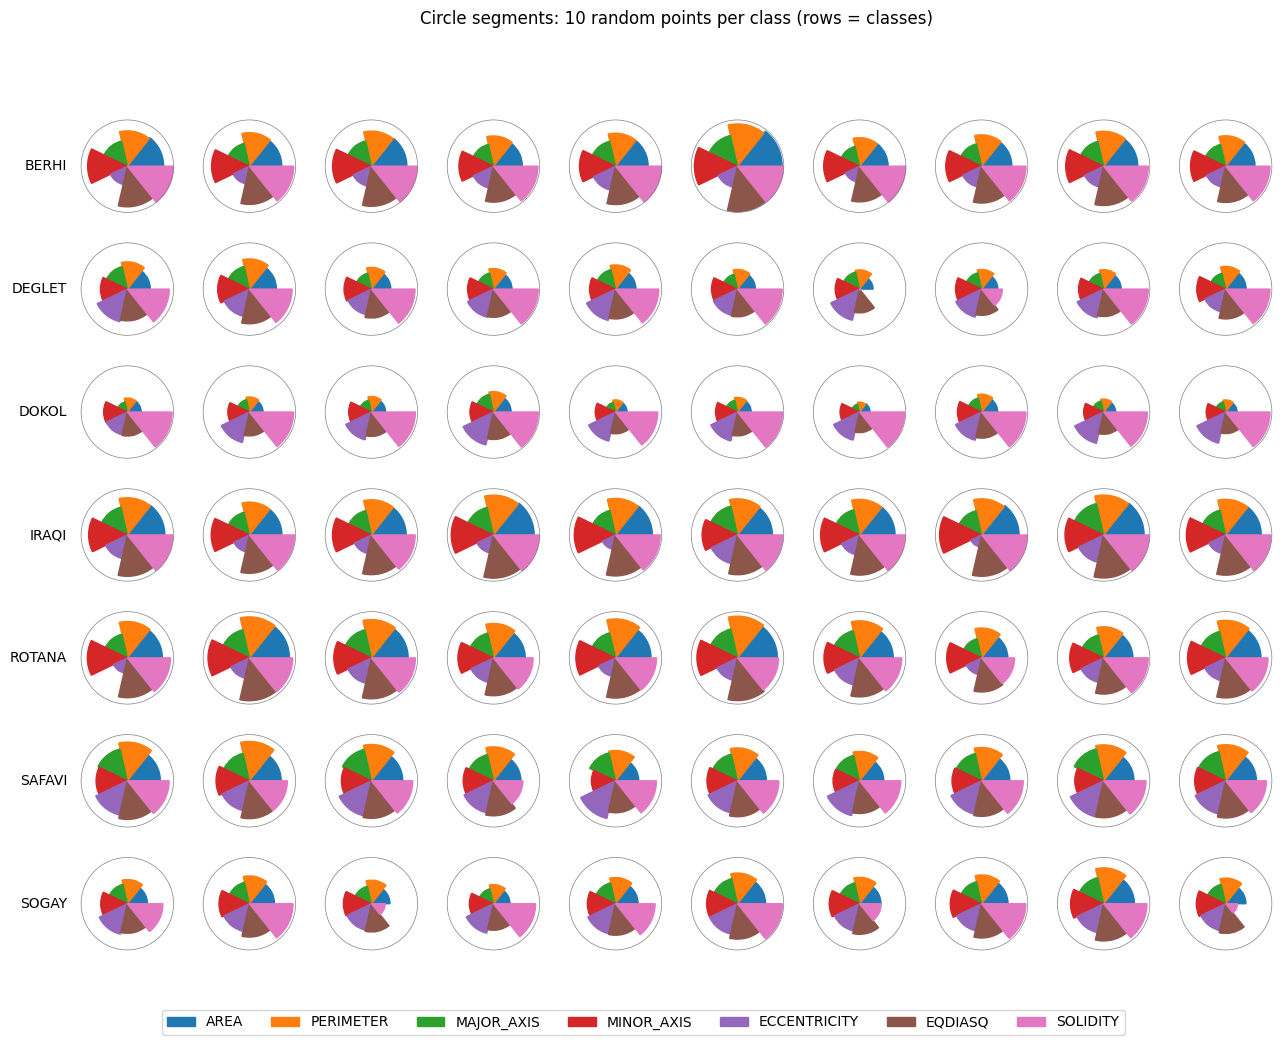

In [ ]:
first7 = df_full.iloc[:, :7]
names7 = list(first7.columns)
scaled7 = ((first7 - first7.min()) / (first7.max() - first7.min())).to_numpy()

per_class = 10
rng = np.random.default_rng(0)
seg_colors = plt.cm.tab10(np.arange(7))

fig, axes = plt.subplots(len(class_names), per_class,
                         figsize=(per_class * 1.5, len(class_names) * 1.5))
for k, name in enumerate(class_names):
    chosen = rng.choice(np.where(y == k)[0], per_class, replace=False)
    for j, row in enumerate(chosen):
        ax = axes[k, j]
        for d in range(7):
            ax.add_patch(Wedge((0, 0), max(scaled7[row, d], 0.03),
                               d * 360 / 7, (d + 1) * 360 / 7, color=seg_colors[d]))
        ax.add_patch(Circle((0, 0), 1, fill=False, linewidth=0.5, color="gray"))
        ax.set_xlim(-1.1, 1.1)
        ax.set_ylim(-1.1, 1.1)
        ax.set_aspect("equal")
        ax.axis("off")
    axes[k, 0].text(-1.3, 0, name, ha="right", va="center", fontsize=10)

fig.legend(handles=[Patch(color=seg_colors[d], label=names7[d]) for d in range(7)],
           loc="lower center", ncol=7)
fig.suptitle("Circle segments: 10 random points per class (rows = classes)")
fig.subplots_adjust(left=0.1, bottom=0.08)
plt.show()

## Task 16: Parallel coordinates (first 7 dimensions)

Each data point becomes one line that crosses 7 parallel vertical axes, one axis per dimension. The line colour shows the class. Each axis is labelled with the feature name and shows the real units of that feature.

After the plot we calculate the mean and standard deviation of each dimension so we can compare them with what we see on the axes.

In [ ]:
df7 = first7.copy()
df7["class_index"] = y

fig = px.parallel_coordinates(df7, dimensions=names7, color="class_index",
                              color_continuous_scale=colors[:7],
                              title="Parallel coordinates of the first 7 dimensions")
fig.update_coloraxes(cmin=0, cmax=6,
                     colorbar=dict(title="Class", tickvals=list(range(7)), ticktext=class_names))
fig.update_layout(width=1200, height=550)
fig.show()

In [ ]:
X7 = first7.to_numpy()
Xc7 = X7 - X7.mean(axis=0)
std7 = np.sqrt(np.diag(Xc7.T @ Xc7) / X7.shape[0])

print(pd.DataFrame({"min": X7.min(axis=0), "mean": X7.mean(axis=0),
                    "std": std7, "max": X7.max(axis=0)}, index=names7))

                    min           mean            std          max
AREA          1987.0000  298295.207127  107185.475338  546063.0000
PERIMETER      911.8280    2057.660953     409.784104    2811.9971
MAJOR_AXIS     336.7227     750.811994     143.979092    1222.7230
MINOR_AXIS       2.2832     495.872785     114.205275     766.4536
ECCENTRICITY     0.3448       0.737468       0.088678       1.0000
EQDIASQ         50.2984     604.577938     119.527281     833.8279
SOLIDITY         0.8366       0.981840       0.018147       0.9974


### Reading the result

- On each axis, most lines should bunch up around the **mean** printed in the table, and the spread of the bunch matches the **standard deviation**.
- For the first three dimensions, the means and standard deviations in this table match the values from task 11.
- Axes where the class colours separate cleanly are the most useful for telling the classes apart.